<a href="https://colab.research.google.com/github/AntonioAldamaG/CarritoCompras/blob/main/Unidad3/Proyecto_Integrador_U3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
import pandas as pd

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


##**ANALISIS DE DATOS**

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
train.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


###**EDA (SUPERVIVENCIA POR SEXO)**

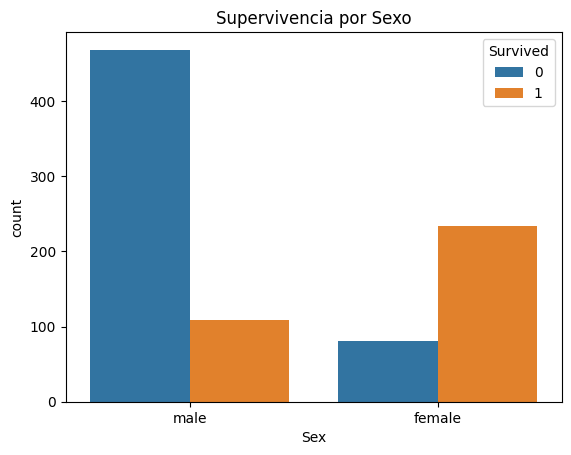

In [ ]:
sns.countplot(data=train, x='Sex', hue='Survived')
plt.title('Supervivencia por Sexo')
plt.show()

###**EDA (SUPERVIVENCIA POR CLASE)**

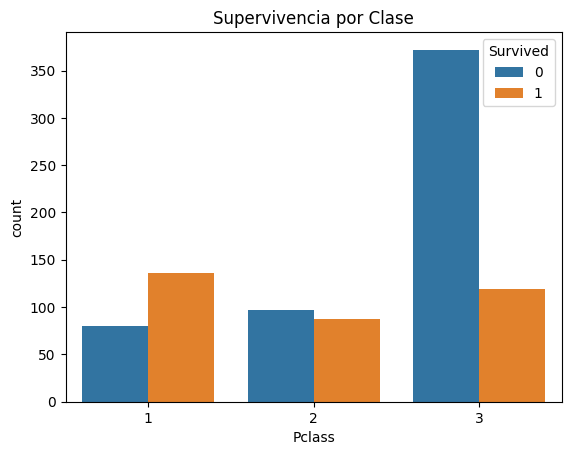

In [ ]:
sns.countplot(data=train, x='Pclass', hue='Survived')
plt.title('Supervivencia por Clase')
plt.show()

###**EDA (SUPERVIVENCIA POR EDAD)**

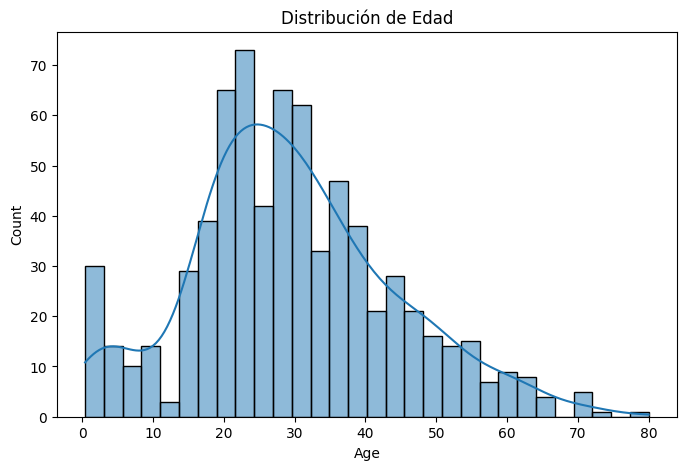

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(train['Age'], bins=30, kde=True)
plt.title('Distribución de Edad')
plt.show()

###**LIMPIEZA DE VALORES NULOS**

In [ ]:
train['Age'].fillna(train['Age'].median(), inplace=True)

train['Embarked'].fillna(train['Embarked'].mode()[0], inplace=True)

train.drop('Cabin', axis=1, inplace=True)

/tmp/ipykernel_4367/844828929.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train['Age'].fillna(train['Age'].median(), inplace=True)
/tmp/ipykernel_4367/844828929.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)'

###**SELECCION DE VARIABLES SIGNIFICATIVAS**

In [ ]:
df = train[['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked','Survived']]

###**CODIFICAR VARIABLES CATEGORICAS**

In [ ]:
df['Sex'] = df['Sex'].map({'male':0,'female':1})

/tmp/ipykernel_4367/2591550582.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Sex'] = df['Sex'].map({'male':0,'female':1})


In [ ]:
le = LabelEncoder()

df['Embarked'] = le.fit_transform(df['Embarked'])

/tmp/ipykernel_4367/14551179.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Embarked'] = le.fit_transform(df['Embarked'])


###**VARIABLE OBJETIVO**

In [ ]:
X = df.drop('Survived', axis=1)

y = df['Survived']

###**DIVISION DEL DATASET**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

###**ESCALAMIENTO DE VARIABLES NUMERICAS**

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

### **¿Por qué escalar en KNN y SVM?**

* **KNN (K-Nearest Neighbors):** Se basa en el cálculo de **distancias** (como la distancia euclidiana) entre puntos para determinar cuáles son los vecinos más cercanos. Si una característica tiene valores en un rango muy grande (por ejemplo, `Fare` de 0 a 500) y otra en un rango muy pequeño (por ejemplo, `Age` de 0 a 80 o `SibSp` de 0 a 8), la variable con el rango más grande dominará por completo el cálculo de la distancia, haciendo que la otra variable sea ignorada en la práctica.
* **SVM (Support Vector Machines):** Intenta encontrar el hiperplano que maximiza el **margen** entre clases. Al calcular este margen, se utilizan productos escalares y distancias al hiperplano. Si las características no están en la misma escala, los gradientes durante la optimización pueden oscilar y el algoritmo tardará mucho más en converger (o no convergerá correctamente), además de dar un peso desproporcionado a las variables con magnitudes mayores.

### **¿Por qué no es necesario en árboles de decisión (y Random Forest)?**

* Los modelos basados en árboles realizan **divisiones (splits)** basadas en reglas de umbral individuales para cada característica (por ejemplo: `¿Age > 30?` o `¿Fare > 50?`).
* Cada característica se analiza de forma **independiente** en cada nodo. La decisión de dividir en una variable no se ve afectada por la escala de las demás variables del conjunto de datos. Monótonamente, cualquier transformación de escala (como multiplicar por 100 o aplicar un logaritmo) mantendría exactamente el mismo orden de los datos y, por lo tanto, produciría las mismas divisiones.

##**ENTRENAMIENTO DE MODELOS**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
modelos = {
    "KNN": KNeighborsClassifier(),
    "Regresion Logistica": LogisticRegression(),
    "Arbol de Decision": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC()
}

###**Entrenamiento y evalución**


KNN
              precision    recall  f1-score   support

           0       0.81      0.85      0.83       165
           1       0.74      0.68      0.71       103

    accuracy                           0.79       268
   macro avg       0.78      0.77      0.77       268
weighted avg       0.79      0.79      0.79       268



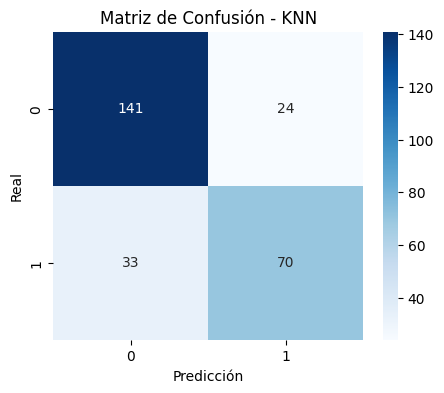


Regresion Logistica
              precision    recall  f1-score   support

           0       0.82      0.85      0.84       165
           1       0.74      0.71      0.73       103

    accuracy                           0.79       268
   macro avg       0.78      0.78      0.78       268
weighted avg       0.79      0.79      0.79       268



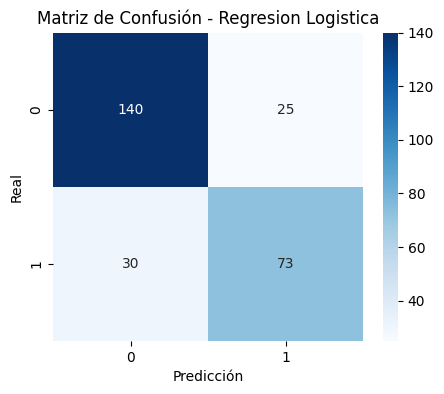


Arbol de Decision
              precision    recall  f1-score   support

           0       0.78      0.82      0.80       165
           1       0.69      0.64      0.66       103

    accuracy                           0.75       268
   macro avg       0.74      0.73      0.73       268
weighted avg       0.75      0.75      0.75       268



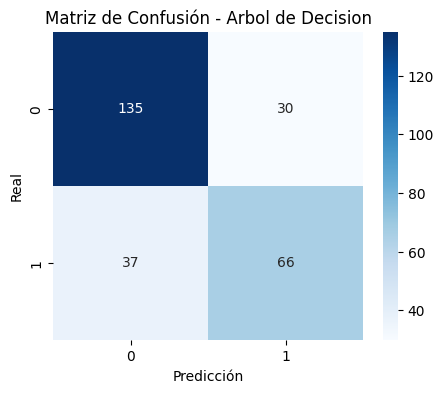


Random Forest
              precision    recall  f1-score   support

           0       0.80      0.87      0.83       165
           1       0.76      0.66      0.70       103

    accuracy                           0.79       268
   macro avg       0.78      0.76      0.77       268
weighted avg       0.78      0.79      0.78       268



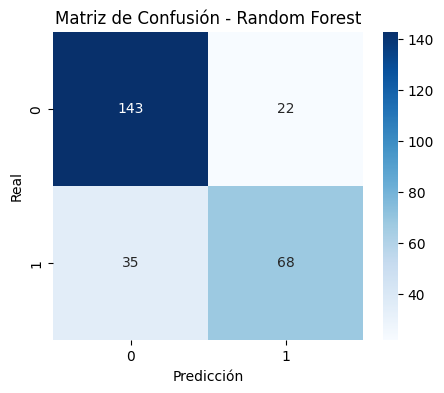


SVM
              precision    recall  f1-score   support

           0       0.81      0.88      0.85       165
           1       0.78      0.68      0.73       103

    accuracy                           0.80       268
   macro avg       0.80      0.78      0.79       268
weighted avg       0.80      0.80      0.80       268



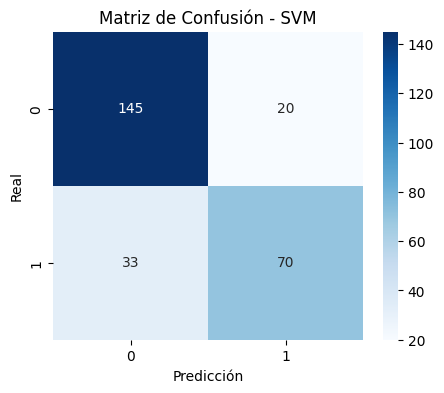

In [ ]:
resultados = []

for nombre, modelo in modelos.items():

    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_test)

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    resultados.append([
        nombre,
        accuracy,
        precision,
        recall,
        f1
    ])

    print(f"\n{'='*50}")
    print(nombre)
    print('='*50)

    print(classification_report(y_test, pred))

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(f'Matriz de Confusión - {nombre}')
    plt.xlabel('Predicción')
    plt.ylabel('Real')

    plt.show()

##**Interpretación individual**

###**KNN (K-Nearest Neightbors)**
**Funcionamiento:**
Clasifica un pasajero según los pasajeros más parecidos cercanos a él.

**Ventajas:**

Fácil de implementar.
Buenos resultados con datos bien escalados.

**Limitaciones:**

Sensible al ruido.
Requiere escalamiento de datos.

**Interpretación de resultados**

Detecta de forma aceptable a los sobrevivientes.

También identifica correctamente una gran parte de los no sobrevivientes, aunque comete algunos errores cuando los pasajeros tienen características similares.

**Posibles causas del rendimiento**

El dataset contiene variables que permiten identificar patrones claros.

Algunos pasajeros tienen características muy parecidas, lo que puede generar confusión.

**Recomendaciones de mejora**

Ajustar el valor de K.

Seleccionar variables más relevantes.

Crear nuevas características derivadas.

###**Regresión Logística**
**Funcionamiento:**
Calcula la probabilidad de que un pasajero sobreviva o no.

**Ventajas:**

Fácil de interpretar.
Rápida de entrenar.

**Limitaciones:**

Puede tener dificultades con relaciones complejas entre variables.

**Interpretación de resultados**

Detecta correctamente tanto sobrevivientes como no sobrevivientes.

Presenta uno de los mejores balances entre precisión y recall.

**Posibles causas del rendimiento**

Las variables seleccionadas tienen una relación significativa con la supervivencia.

**Recomendaciones de mejora**

Incorporar más variables relevantes.

Realizar ingeniería de características.

Ajustar hiperparámetros.

###**Árbol de Decisión**

**Funcionamiento:**
 Genera reglas de decisión basadas en las características de los pasajeros.

 **Ventajas:**

Fácil de comprender.

No requiere escalamiento.

**Limitaciones:**

Puede sobreajustarse.

**Interpretación de resultados**

Fue el modelo con menor accuracy.

Detecta razonablemente a ambos grupos, pero con más errores que los demás modelos.

**Posibles causas del rendimiento**

El árbol puede haber aprendido patrones demasiado específicos del conjunto de entrenamiento.

**Recomendaciones de mejora**

Limitar la profundidad del árbol.

Aplicar poda.

Optimizar hiperparámetros.

###**Random Forest**
**Funcionamiento:** Combina múltiples árboles de decisión para obtener una predicción más precisa.

**Ventajas:**

Alta precisión.
Reduce el sobreajuste.

**Limitaciones:**

Más difícil de interpretar que un árbol individual.

**Interpretación de resultados**

Obtuvo un rendimiento competitivo.

Detecta adecuadamente sobrevivientes y no sobrevivientes.

**Posibles causas del rendimiento**

La combinación de varios árboles mejora la capacidad de generalización.

**Recomendaciones de mejora**

Ajustar número de árboles.

Optimizar profundidad y criterios de división.

Incorporar nuevas variables.


###**SVM (Support Vector Machine)**
**Funcionamiento:** Busca la mejor frontera para separar pasajeros sobrevivientes y no sobrevivientes.

**Ventajas:**

Buen rendimiento en clasificación.
Eficaz con datos complejos.

**Limitaciones:**

Requiere escalamiento.
Puede ser lento con grandes volúmenes de datos.

**Interpretación de resultados**

Fue el mejor modelo del proyecto con un Accuracy de 80.22%.

Detecta correctamente la mayoría de los pasajeros.

Presentó el mejor desempeño general entre todos los algoritmos evaluados.

**Posibles causas del rendimiento**

La frontera de separación encontrada por SVM se adapta bien a los patrones del dataset Titanic.

**Recomendaciones de mejora**

Ajustar parámetros como C y gamma.

Realizar validación cruzada.

Aplicar ingeniería de características.

##**Comparación de resultados**

###**Tabla comparativa**

In [ ]:
comparacion = pd.DataFrame(
    resultados,
    columns=[
        'Modelo',
        'Accuracy',
        'Precision',
        'Recall',
        'F1'
    ]
)

comparacion.sort_values(
    by='Accuracy',
    ascending=False
)

,Modelo,Accuracy,Precision,Recall,F1
4,SVM,0.802239,0.777778,0.679612,0.725389
1,Regresion Logistica,0.794776,0.744898,0.708738,0.726368
0,KNN,0.787313,0.744681,0.679612,0.710660
3,Random Forest,0.787313,0.755556,0.660194,0.704663
2,Arbol de Decision,0.750000,0.687500,0.640777,0.663317


###**Gráfica comparativa**

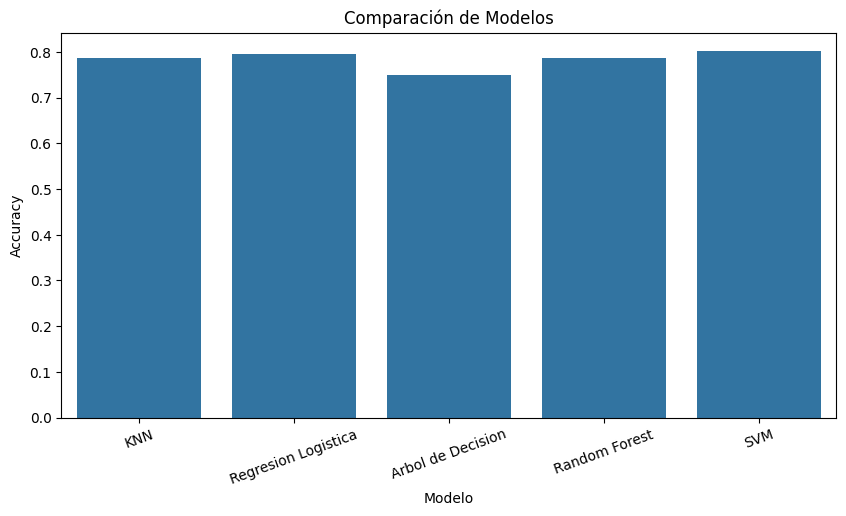

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=comparacion,
    x='Modelo',
    y='Accuracy'
)

plt.title('Comparación de Modelos')
plt.xticks(rotation=20)

plt.show()

###**Análisis comparativo**

Al comparar los cinco modelos de clasificación, se observó que SVM obtuvo el mejor desempeño con un Accuracy de 80.22%. La Regresión Logística presentó un rendimiento muy similar, además de obtener el mejor balance entre Precision, Recall y F1-Score. KNN y Random Forest mostraron resultados competitivos, mientras que el Árbol de Decisión fue el modelo con menor rendimiento general. Los resultados indican que los modelos evaluados son capaces de identificar correctamente patrones relacionados con la supervivencia de los pasajeros del Titanic.

###**Conclusiones**
Después de entrenar y evaluar cinco modelos de clasificación para el dataset Titanic, se observó que el modelo SVM obtuvo la mayor exactitud, aproximadamente del 80%. Los modelos Random Forest, KNN y Regresión Logística mostraron un desempeño similar y competitivo. El Árbol de Decisión presentó la menor exactitud entre los modelos evaluados. En general, todos los algoritmos lograron predecir adecuadamente la supervivencia de los pasajeros, siendo SVM la mejor opción para este conjunto de datos.

##**Recomendaciones técnicas**

###**KNN (K-Nearest Neighbors)**

Se recomienda utilizar KNN cuando se trabaja con conjuntos de datos pequeños o medianos y cuando las observaciones presentan patrones de similitud claros. Este algoritmo requiere que las variables sean escaladas previamente, ya que basa sus decisiones en el cálculo de distancias entre los datos. Es una buena opción para problemas con fronteras de decisión relativamente simples.

###**Regresión Logística**

La Regresión Logística es recomendable cuando se necesita interpretar fácilmente los resultados y analizar la influencia de cada variable en la predicción. Es un modelo eficiente, rápido de entrenar y adecuado para problemas donde existe una relación relativamente lineal entre las variables y la clase objetivo.

###**Árbol de Decisión**

Los Árboles de Decisión son ideales cuando se requiere comprender claramente cómo se toman las decisiones dentro del modelo. No necesitan escalamiento de datos y permiten visualizar reglas de clasificación de forma sencilla. Sin embargo, es importante controlar el sobreajuste mediante ajustes en la profundidad del árbol o técnicas de poda.

###**Random Forest**

Random Forest es una excelente opción cuando se busca un modelo robusto y con buena capacidad de generalización. Al combinar múltiples árboles de decisión reduce el riesgo de sobreajuste y suele ofrecer buenos resultados en problemas de clasificación con múltiples variables y presencia de ruido en los datos.

###**SVM (Support Vector Machine)**

SVM es especialmente útil cuando se busca una alta precisión en problemas de clasificación. Este algoritmo requiere escalamiento de variables y suele funcionar muy bien cuando existen fronteras de decisión complejas entre las clases. En este proyecto fue el modelo que obtuvo el mejor desempeño general, por lo que representa una alternativa recomendable para la predicción de supervivencia en el conjunto de datos Titanic.

##**Reflexión final**

**¿Qué modelo funcionó mejor y por qué?**

El modelo que obtuvo el mejor desempeño fue SVM (Support Vector Machine), alcanzando una exactitud del 80.22%. Este resultado indica que fue el algoritmo con mayor capacidad para diferenciar entre los pasajeros que sobrevivieron y los que no sobrevivieron. Su buen rendimiento se debe a que encuentra una frontera óptima que separa las clases, permitiendo realizar predicciones más precisas.

**¿Qué variables influyen más en la supervivencia?**

Las variables que mostraron mayor influencia en la supervivencia fueron el sexo, la clase del pasajero (Pclass) y la edad. Durante el análisis exploratorio se observó que las mujeres presentaron mayores tasas de supervivencia que los hombres. Asimismo, los pasajeros de primera clase tuvieron una probabilidad más alta de sobrevivir en comparación con los de segunda y tercera clase. La edad también influyó, ya que los pasajeros más jóvenes tendieron a tener mayores posibilidades de supervivencia.

**¿Qué patrones sociales se observan?**

Los resultados muestran algunos patrones sociales importantes. Se observó que las mujeres sobrevivieron en una proporción mayor que los hombres, lo que coincide con la política de evacuación conocida como "mujeres y niños primero". También se identificó que los pasajeros de clases más altas tuvieron mejores oportunidades de acceso a los botes salvavidas y a las zonas de evacuación. Estos patrones sugieren que tanto el género como la posición socioeconómica influyeron significativamente en las probabilidades de supervivencia.

**¿Qué decisiones se podrían tomar con este análisis?**

Este análisis demuestra cómo los modelos de Machine Learning pueden identificar factores asociados con la supervivencia en situaciones de emergencia. A partir de estos resultados, podrían diseñarse estrategias para mejorar protocolos de evacuación, priorizar grupos vulnerables y optimizar la distribución de recursos durante situaciones críticas. Además, el proyecto confirma la importancia de analizar datos históricos para comprender patrones de comportamiento y apoyar la toma de decisiones basada en evidencia.